<a href="https://colab.research.google.com/github/reyyan16/cmapss-rul-tahmini/blob/main/01_EDA_ve_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!wget -q https://data.nasa.gov/docs/legacy/CMAPSSData.zip
!unzip -q CMAPSSData.zip -d CMAPSS
!ls CMAPSS

'Damage Propagation Modeling.pdf'   RUL_FD004.txt    train_FD001.txt
 readme.txt			    test_FD001.txt   train_FD002.txt
 RUL_FD001.txt			    test_FD002.txt   train_FD003.txt
 RUL_FD002.txt			    test_FD003.txt   train_FD004.txt
 RUL_FD003.txt			    test_FD004.txt


In [3]:
import pandas as pd, matplotlib.pyplot as plt

cols = ['motor','dongu','ayar1','ayar2','ayar3'] + [f's{i}' for i in range(1,22)]
df = pd.read_csv('CMAPSS/train_FD001.txt', sep=r'\s+', header=None, names=cols)

df['RUL'] = df.groupby('motor')['dongu'].transform('max') - df['dongu']
omur = df.groupby('motor')['dongu'].max()

print('Satır sayısı :', len(df))
print('Motor sayısı :', df.motor.nunique())
print('Sensör sayısı:', 21)
print(f'Motor ömrü   : min {omur.min()}, ort {omur.mean():.0f}, max {omur.max()} döngü')

Satır sayısı : 20631
Motor sayısı : 100
Sensör sayısı: 21
Motor ömrü   : min 128, ort 206, max 362 döngü


In [4]:
sensorler = [f's{i}' for i in range(1,22)]
std = df[sensorler].std()
sabit = std[std < 0.01].index.tolist()
print('Sabit (atılacak) sensörler:', sabit)
print('Kullanılacak sensörler  :', [s for s in sensorler if s not in sabit])

Sabit (atılacak) sensörler: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
Kullanılacak sensörler  : ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


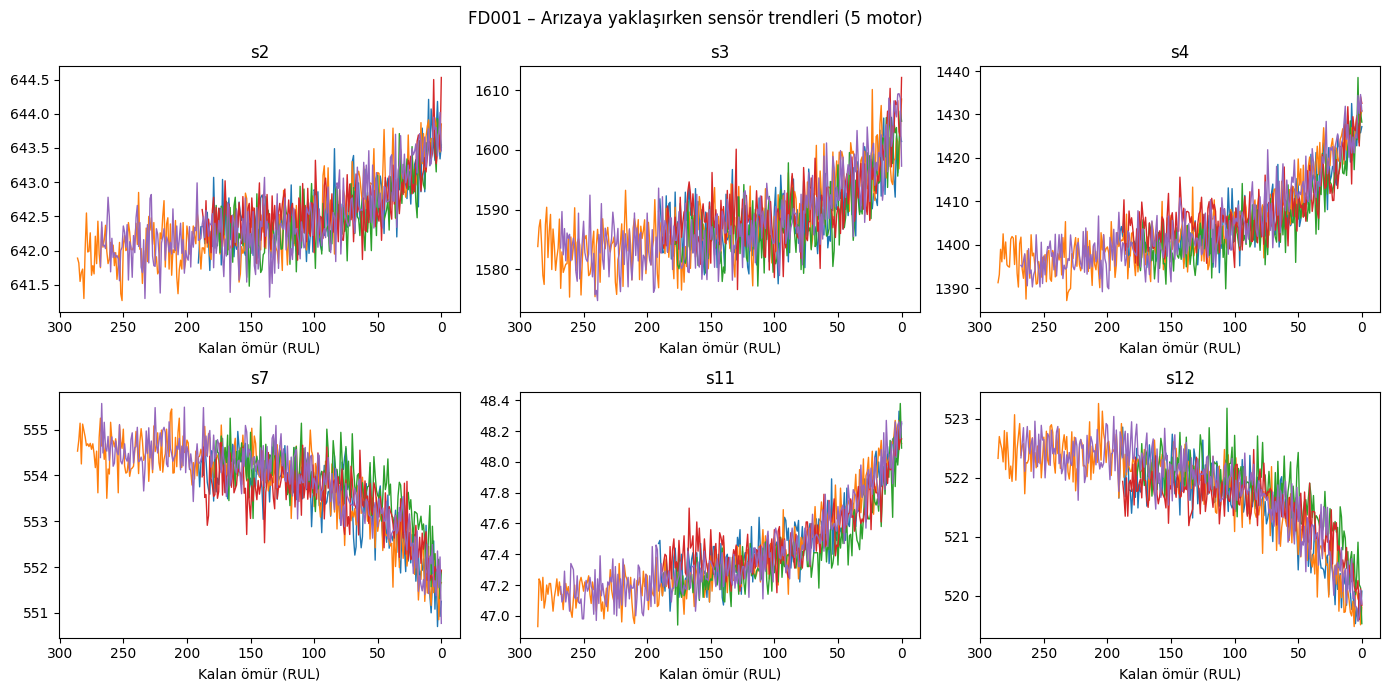

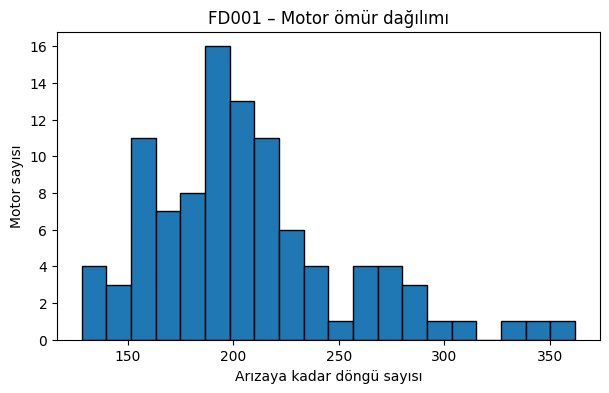

In [5]:
# Grafik 1: Sensörlerin arızaya yaklaşırken değişimi
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, s in zip(ax.flat, ['s2','s3','s4','s7','s11','s12']):
    for m in [1, 2, 3, 4, 5]:
        d = df[df.motor == m]
        a.plot(d.RUL, d[s], lw=1)
    a.invert_xaxis(); a.set_title(s); a.set_xlabel('Kalan ömür (RUL)')
plt.suptitle('FD001 – Arızaya yaklaşırken sensör trendleri (5 motor)')
plt.tight_layout(); plt.savefig('sensor_trendleri.png', dpi=150); plt.show()

# Grafik 2: Motor ömür dağılımı
plt.figure(figsize=(7, 4))
plt.hist(omur, bins=20, edgecolor='k')
plt.xlabel('Arızaya kadar döngü sayısı'); plt.ylabel('Motor sayısı')
plt.title('FD001 – Motor ömür dağılımı')
plt.savefig('omur_dagilimi.png', dpi=150); plt.show()

              Model   RMSE  NASA Skoru
0  Lineer Regresyon  20.82      1251.0
1     Random Forest  17.31       944.0


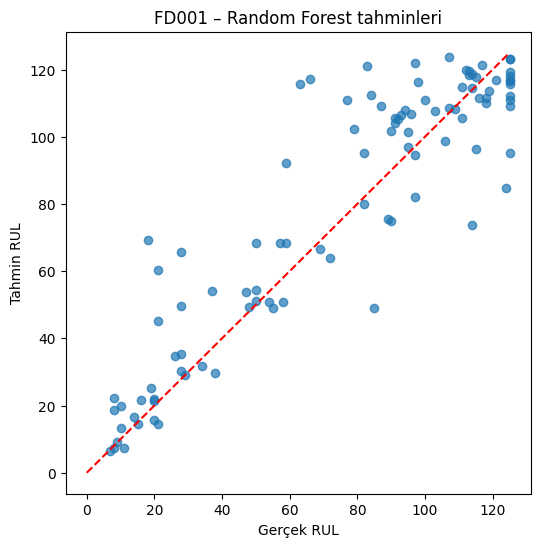

In [6]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

kullan = [s for s in sensorler if s not in sabit]
df['RUL_k'] = df['RUL'].clip(upper=125)   # literatürdeki standart: RUL üst sınırı 125

# Test: her motorun son döngüsü + gerçek RUL
test = pd.read_csv('CMAPSS/test_FD001.txt', sep=r'\s+', header=None, names=cols)
test_son = test.groupby('motor').last()
gercek = pd.read_csv('CMAPSS/RUL_FD001.txt', header=None)[0].clip(upper=125).values

def nasa_skor(y, p):
    d = p - y
    return np.sum(np.where(d < 0, np.exp(-d/13) - 1, np.exp(d/10) - 1))

modeller = {'Lineer Regresyon': LinearRegression(),
            'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=12, n_jobs=-1, random_state=42)}
sonuc = []
for ad, m in modeller.items():
    m.fit(df[kullan], df['RUL_k'])
    p = m.predict(test_son[kullan])
    rmse = np.sqrt(np.mean((p - gercek) ** 2))
    sonuc.append([ad, round(rmse, 2), round(nasa_skor(gercek, p), 0)])
print(pd.DataFrame(sonuc, columns=['Model', 'RMSE', 'NASA Skoru']))

# Grafik: Tahmin vs gerçek (Random Forest)
plt.figure(figsize=(6, 6))
plt.scatter(gercek, p, alpha=.7); plt.plot([0, 125], [0, 125], 'r--')
plt.xlabel('Gerçek RUL'); plt.ylabel('Tahmin RUL'); plt.title('FD001 – Random Forest tahminleri')
plt.savefig('rf_tahmin.png', dpi=150); plt.show()